# Домашнее задание 2 (CNN)



**Датасет:** Brain Tumor MRI Dataset (Kaggle) — МРТ головного мозга, 4 класса: glioma, meningioma, pituitary (опухоли) и notumor (норма).

In [ ]:
%pip install kagglehub --quiet

In [ ]:
import kagglehub

path = kagglehub.dataset_download("masoudnickparvar/brain-tumor-mri-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'brain-tumor-mri-dataset' dataset.
Path to dataset files: /kaggle/input/brain-tumor-mri-dataset


In [ ]:
import os, time, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay, f1_score

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else
                      "mps" if torch.backends.mps.is_available() else "cpu")
print("device:", device)

IMG_SIZE   = 128
BATCH_SIZE = 64
EPOCHS_CNN = 15
EPOCHS_RES = 5
LR_CNN     = 1e-3
LR_RES     = 1e-4

device: cuda


## 1. Данные

В датасете две папки: Training и Testing, внутри — папки по классам. Используем Testing как тестовую выборку,
а Training делим на train (85%) и val (15%) со стратификацией по классам.


/kaggle/input/brain-tumor-mri-dataset ['Training', 'Testing']


,Training,Testing
glioma,1400,400
meningioma,1400,400
notumor,1400,400
pituitary,1400,400


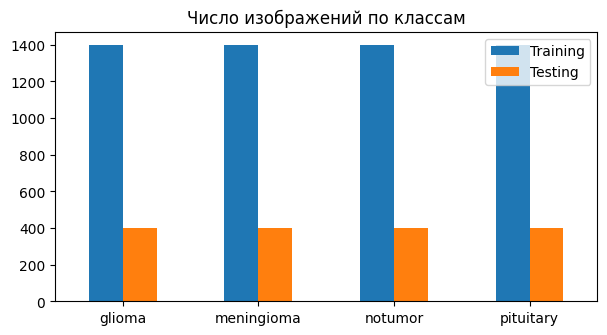

In [ ]:
def find_root(p):
    for r, dirs, _ in os.walk(p):
        if "Training" in dirs and "Testing" in dirs:
            return r
    raise FileNotFoundError("Не нашла папки Training/Testing в " + p)

ROOT = find_root(path)
TRAIN_DIR, TEST_DIR = os.path.join(ROOT, "Training"), os.path.join(ROOT, "Testing")
print(ROOT, os.listdir(ROOT))

counts = pd.DataFrame({
    split: {c: len(os.listdir(os.path.join(d, c))) for c in sorted(os.listdir(d)) if not c.startswith('.')}
    for split, d in [("Training", TRAIN_DIR), ("Testing", TEST_DIR)]
})
display(counts)
counts.plot(kind="bar", figsize=(7,3.5), title="Число изображений по классам"); plt.xticks(rotation=0); plt.show()

In [ ]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

train_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.15, contrast=0.15),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
eval_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

full_train = datasets.ImageFolder(TRAIN_DIR, transform=train_tf)
full_eval  = datasets.ImageFolder(TRAIN_DIR, transform=eval_tf)
test_ds    = datasets.ImageFolder(TEST_DIR,  transform=eval_tf)
classes = full_train.classes
NUM_CLASSES = len(classes)
assert classes == test_ds.classes

# стратифицированное разбиение train/val
targets = np.array(full_train.targets)
rng = np.random.RandomState(SEED)
tr_idx, va_idx = [], []
for c in range(NUM_CLASSES):
    idx = rng.permutation(np.where(targets == c)[0])
    n_val = int(0.15 * len(idx))
    va_idx += list(idx[:n_val]); tr_idx += list(idx[n_val:])

train_ds = Subset(full_train, tr_idx)
val_ds   = Subset(full_eval,  va_idx)
print("классы:", classes)
print("train/val/test:", len(train_ds), len(val_ds), len(test_ds))

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,  num_workers=2)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

классы: ['glioma', 'meningioma', 'notumor', 'pituitary']
train/val/test: 4760 840 1600


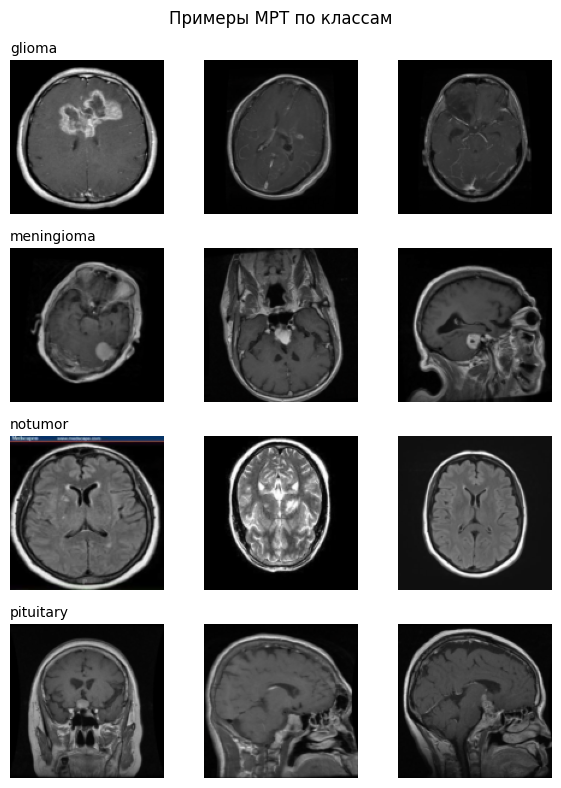

In [ ]:
def denorm(x):
    m = torch.tensor(MEAN).view(3,1,1); s = torch.tensor(STD).view(3,1,1)
    return (x*s+m).clamp(0,1)

# по 3 примера каждого класса
fig, axes = plt.subplots(NUM_CLASSES, 3, figsize=(6, 2*NUM_CLASSES))
for c in range(NUM_CLASSES):
    ids = np.where(np.array(test_ds.targets) == c)[0][:3]
    for j, i in enumerate(ids):
        img, _ = test_ds[i]
        axes[c, j].imshow(denorm(img).permute(1,2,0)); axes[c, j].axis("off")
        if j == 0: axes[c, j].set_title(classes[c], fontsize=10, loc="left")
plt.suptitle("Примеры МРТ по классам"); plt.tight_layout(); plt.show()

## Собственная модель SimpleCNN

In [ ]:
class SimpleCNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        def block(cin, cout):
            return nn.Sequential(
                nn.Conv2d(cin, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
                nn.Conv2d(cout, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
                nn.MaxPool2d(2),
            )
        self.features = nn.Sequential(block(3, 32), block(32, 64), block(64, 128), block(128, 256))
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.head = nn.Sequential(nn.Flatten(), nn.Dropout(0.4), nn.Linear(256, 128),
                                  nn.ReLU(inplace=True), nn.Dropout(0.3), nn.Linear(128, num_classes))
    def forward(self, x):
        return self.head(self.pool(self.features(x)))

def count_params(m, trainable_only=False):
    return sum(p.numel() for p in m.parameters() if (p.requires_grad or not trainable_only))

simple_cnn = SimpleCNN(NUM_CLASSES).to(device)
print(simple_cnn)
print("Параметров:", count_params(simple_cnn))

SimpleCNN(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (5): ReLU(inplace=True)
      (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (5): ReLU(inplace=True)
      (6): MaxPool2d(kernel_size=2, st

## 3. Функции обучения и оценки

In [ ]:
def run_epoch(model, loader, criterion, optimizer=None):
    train = optimizer is not None
    model.train(train)
    total_loss, correct, total = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss = criterion(out, y)
            if train:
                optimizer.zero_grad(); loss.backward(); optimizer.step()
            total_loss += loss.item()*x.size(0)
            correct += (out.argmax(1) == y).sum().item()
            total += x.size(0)
    return total_loss/total, correct/total

def fit(model, epochs, lr, name):
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=lr)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, factor=0.5, patience=2)
    hist = {"train_loss":[], "val_loss":[], "train_acc":[], "val_acc":[]}
    best_acc, best_state = 0, None
    t0 = time.time()
    for ep in range(1, epochs+1):
        tl, ta = run_epoch(model, train_loader, criterion, optimizer)
        vl, va = run_epoch(model, val_loader, criterion)
        scheduler.step(vl)
        for k, v in zip(hist, [tl, vl, ta, va]): hist[k].append(v)
        if va > best_acc:
            best_acc = va; best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        print(f"[{name}] epoch {ep:02d}/{epochs} | train loss {tl:.3f} acc {ta:.3f} | val loss {vl:.3f} acc {va:.3f}")
    model.load_state_dict(best_state)   # возвращаем лучшие по val веса
    hist["time"] = time.time() - t0
    return hist

@torch.no_grad()
def predict(model, loader):
    model.eval(); ys, ps = [], []
    for x, y in loader:
        ps.append(model(x.to(device)).argmax(1).cpu()); ys.append(y)
    return torch.cat(ys).numpy(), torch.cat(ps).numpy()

## 4. Обучение SimpleCNN

In [ ]:
hist_cnn = fit(simple_cnn, EPOCHS_CNN, LR_CNN, 'SimpleCNN')
print(f"Время обучения: {hist_cnn['time']:.0f} c")

[SimpleCNN] epoch 01/15 | train loss 0.778 acc 0.685 | val loss 0.952 acc 0.601
[SimpleCNN] epoch 02/15 | train loss 0.580 acc 0.778 | val loss 0.541 acc 0.789
[SimpleCNN] epoch 03/15 | train loss 0.468 acc 0.818 | val loss 0.590 acc 0.780
[SimpleCNN] epoch 04/15 | train loss 0.427 acc 0.844 | val loss 1.318 acc 0.452
[SimpleCNN] epoch 05/15 | train loss 0.403 acc 0.851 | val loss 1.135 acc 0.640
[SimpleCNN] epoch 06/15 | train loss 0.353 acc 0.869 | val loss 0.343 acc 0.868
[SimpleCNN] epoch 07/15 | train loss 0.312 acc 0.889 | val loss 0.304 acc 0.895
[SimpleCNN] epoch 08/15 | train loss 0.312 acc 0.888 | val loss 0.557 acc 0.815
[SimpleCNN] epoch 09/15 | train loss 0.291 acc 0.899 | val loss 0.586 acc 0.785
[SimpleCNN] epoch 10/15 | train loss 0.258 acc 0.910 | val loss 0.561 acc 0.804
[SimpleCNN] epoch 11/15 | train loss 0.218 acc 0.921 | val loss 0.354 acc 0.854
[SimpleCNN] epoch 12/15 | train loss 0.197 acc 0.931 | val loss 0.152 acc 0.946
[SimpleCNN] epoch 13/15 | train loss 0.1

## 5. Предобученный ResNet18


In [ ]:
resnet = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
resnet.fc = nn.Linear(resnet.fc.in_features, NUM_CLASSES)
resnet = resnet.to(device)
print("Параметров:", count_params(resnet))

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 186MB/s]


Параметров: 11178564


In [ ]:
hist_res = fit(resnet, EPOCHS_RES, LR_RES, 'ResNet18')
print(f"Время обучения: {hist_res['time']:.0f} c")

[ResNet18] epoch 01/5 | train loss 0.369 acc 0.861 | val loss 0.177 acc 0.939
[ResNet18] epoch 02/5 | train loss 0.115 acc 0.960 | val loss 0.110 acc 0.968
[ResNet18] epoch 03/5 | train loss 0.083 acc 0.975 | val loss 0.143 acc 0.951
[ResNet18] epoch 04/5 | train loss 0.049 acc 0.985 | val loss 0.073 acc 0.974
[ResNet18] epoch 05/5 | train loss 0.047 acc 0.984 | val loss 0.078 acc 0.982
Время обучения: 103 c


## 6. Сравнение результатов

Кривые обучения

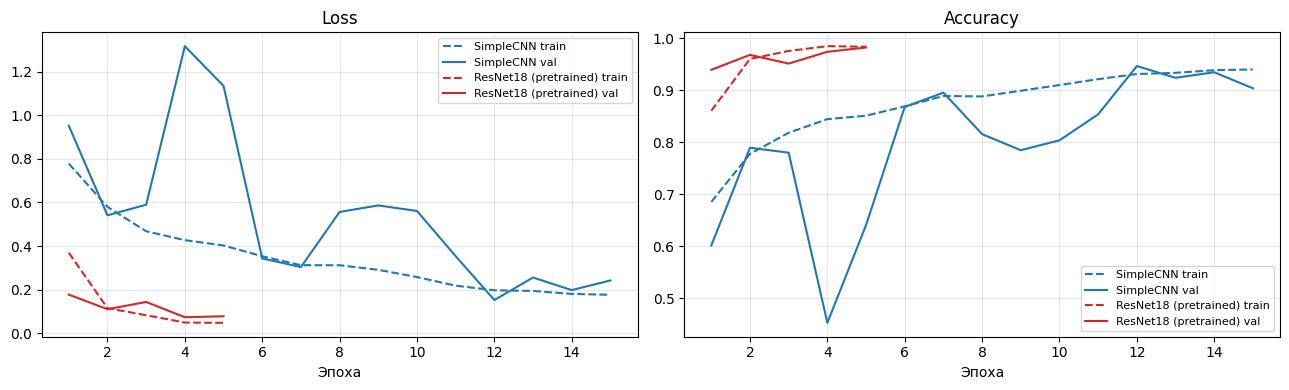

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name, h, c in [("SimpleCNN", hist_cnn, "tab:blue"), ("ResNet18 (pretrained)", hist_res, "tab:red")]:
    ep = range(1, len(h["val_acc"])+1)
    axes[0].plot(ep, h["train_loss"], "--", color=c, label=f"{name} train")
    axes[0].plot(ep, h["val_loss"],   "-",  color=c, label=f"{name} val")
    axes[1].plot(ep, h["train_acc"],  "--", color=c, label=f"{name} train")
    axes[1].plot(ep, h["val_acc"],    "-",  color=c, label=f"{name} val")
axes[0].set_title("Loss"); axes[1].set_title("Accuracy")
for a in axes: a.set_xlabel("Эпоха"); a.grid(alpha=.3); a.legend(fontsize=8)
plt.tight_layout(); plt.show()

Метрики на тестовой выборке

,Модель,Test accuracy,Test macro-F1,Лучшая val accuracy,Параметров,Эпох,"Время обучения, c"
0,SimpleCNN,0.8800,0.8775,0.9464,1207588,15,348.5294
1,ResNet18 (pretrained),0.9381,0.9366,0.9821,11178564,5,102.7807


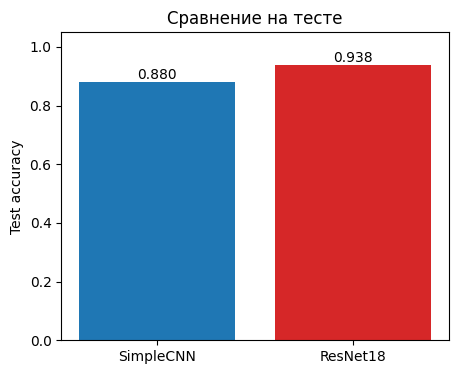

In [ ]:
y_true, y_cnn = predict(simple_cnn, test_loader)
_,      y_res = predict(resnet, test_loader)

summary = pd.DataFrame({
    "Модель": ["SimpleCNN", "ResNet18 (pretrained)"],
    "Test accuracy": [(y_true==y_cnn).mean(), (y_true==y_res).mean()],
    "Test macro-F1": [f1_score(y_true, y_cnn, average="macro"), f1_score(y_true, y_res, average="macro")],
    "Лучшая val accuracy": [max(hist_cnn["val_acc"]), max(hist_res["val_acc"])],
    "Параметров": [count_params(simple_cnn), count_params(resnet)],
    "Эпох": [EPOCHS_CNN, EPOCHS_RES],
    "Время обучения, c": [hist_cnn["time"], hist_res["time"]],
}).round(4)
display(summary)

fig, ax = plt.subplots(figsize=(5,4))
bars = ax.bar(["SimpleCNN", "ResNet18"], summary["Test accuracy"], color=["tab:blue", "tab:red"])
ax.bar_label(bars, fmt="%.3f"); ax.set_ylim(0, 1.05); ax.set_ylabel("Test accuracy"); ax.set_title("Сравнение на тесте")
plt.show()

Матрицы ошибок и метрики по классам

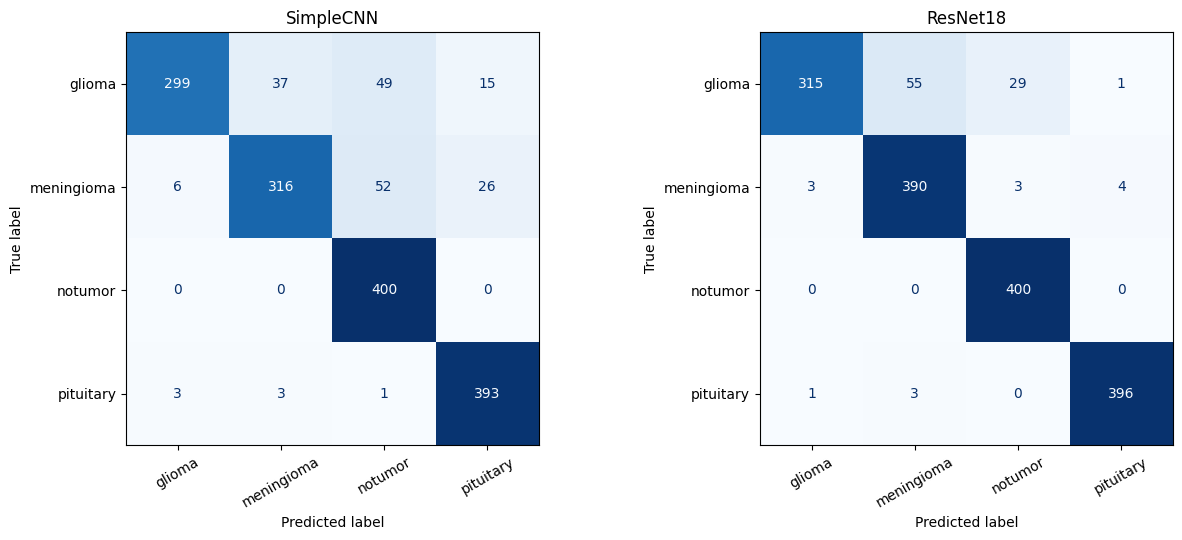

=== SimpleCNN ===
              precision    recall  f1-score   support

      glioma      0.971     0.748     0.845       400
  meningioma      0.888     0.790     0.836       400
     notumor      0.797     1.000     0.887       400
   pituitary      0.906     0.983     0.942       400

    accuracy                          0.880      1600
   macro avg      0.890     0.880     0.877      1600
weighted avg      0.890     0.880     0.877      1600

=== ResNet18 ===
              precision    recall  f1-score   support

      glioma      0.987     0.787     0.876       400
  meningioma      0.871     0.975     0.920       400
     notumor      0.926     1.000     0.962       400
   pituitary      0.988     0.990     0.989       400

    accuracy                          0.938      1600
   macro avg      0.943     0.938     0.937      1600
weighted avg      0.943     0.938     0.937      1600



In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, yp, title in [(axes[0], y_cnn, "SimpleCNN"), (axes[1], y_res, "ResNet18")]:
    cm = confusion_matrix(y_true, yp)
    ConfusionMatrixDisplay(cm, display_labels=classes).plot(ax=ax, cmap="Blues", colorbar=False, xticks_rotation=30)
    ax.set_title(title)
plt.tight_layout(); plt.show()

print("=== SimpleCNN ===");  print(classification_report(y_true, y_cnn, target_names=classes, digits=3))
print("=== ResNet18 ==="); print(classification_report(y_true, y_res, target_names=classes, digits=3))

Примеры предсказаний и ошибки

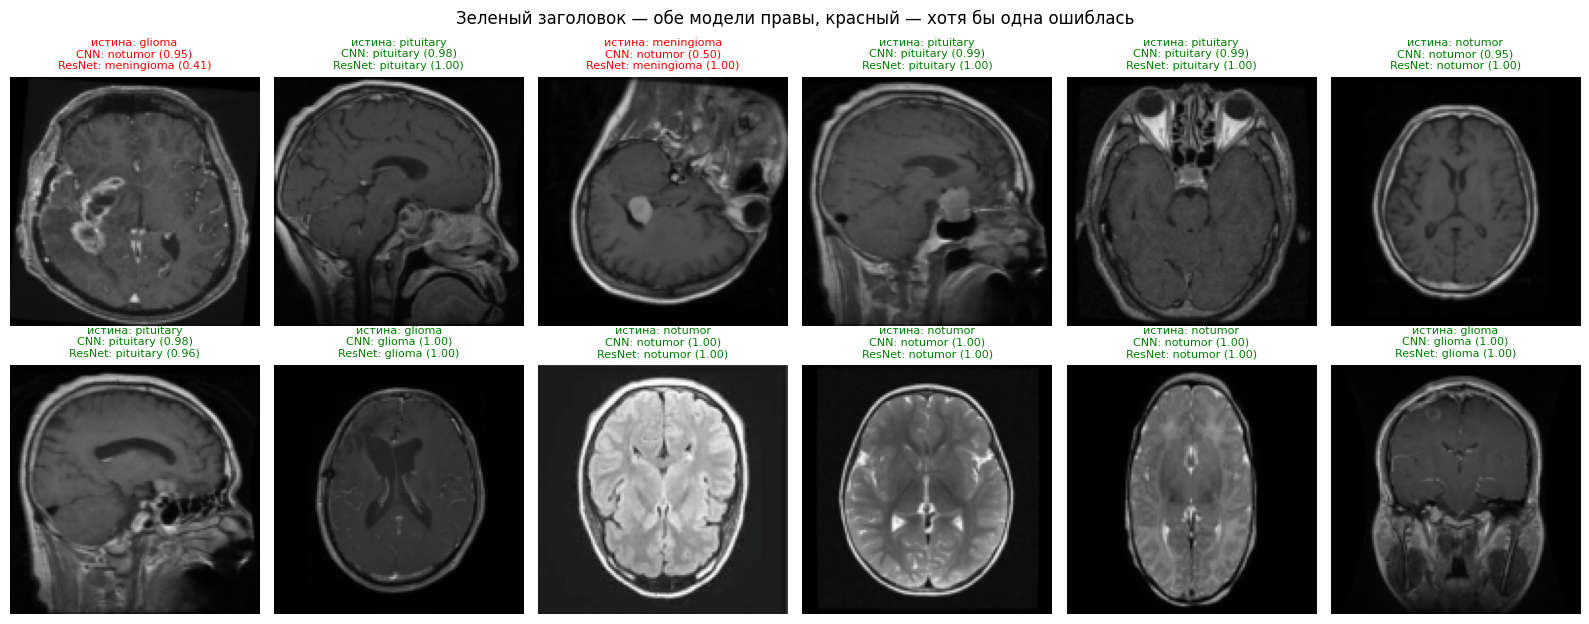

In [ ]:
@torch.no_grad()
def probs(model, x):
    model.eval(); return torch.softmax(model(x.to(device)), 1).cpu()

# случайные 12 картинок из теста
sel = np.random.RandomState(1).choice(len(test_ds), 12, replace=False)
xs = torch.stack([test_ds[i][0] for i in sel]); ys = [test_ds[i][1] for i in sel]
pc, pr = probs(simple_cnn, xs), probs(resnet, xs)

fig, axes = plt.subplots(2, 6, figsize=(16, 6.5))
for ax, img, t, a, b in zip(axes.ravel(), xs, ys, pc, pr):
    ia, ib = a.argmax().item(), b.argmax().item()
    ax.imshow(denorm(img).permute(1,2,0)); ax.axis("off")
    ax.set_title(f"истина: {classes[t]}\nCNN: {classes[ia]} ({a[ia]:.2f})\nResNet: {classes[ib]} ({b[ib]:.2f})",
                 fontsize=8, color="green" if (ia==t and ib==t) else "red")
plt.suptitle("Зеленый заголовок — обе модели правы, красный — хотя бы одна ошиблась"); plt.tight_layout(); plt.show()

Ошиблись обе модели на 86 из 1600 тестовых картинок


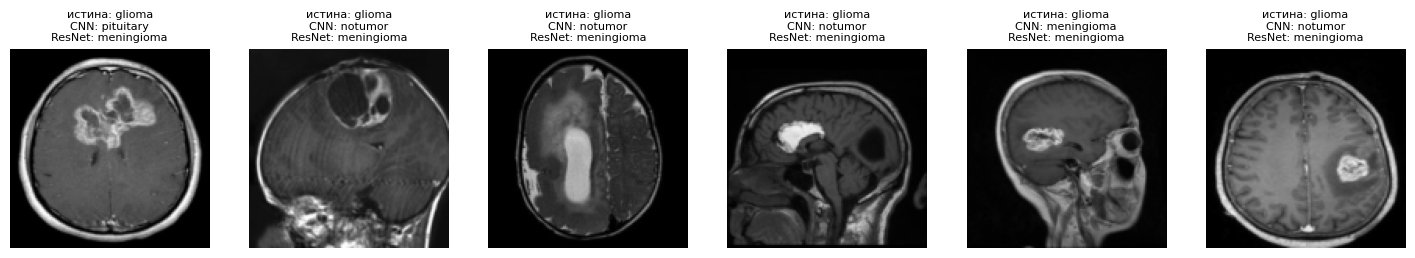

In [ ]:
# Картинки, на которых ошиблись обе модели
both_wrong = np.where((y_cnn != y_true) & (y_res != y_true))[0][:6]
print("Ошиблись обе модели на", int(((y_cnn != y_true) & (y_res != y_true)).sum()), "из", len(y_true), "тестовых картинок")
if len(both_wrong):
    fig, axes = plt.subplots(1, len(both_wrong), figsize=(3*len(both_wrong), 3.4))
    axes = np.atleast_1d(axes)
    for ax, i in zip(axes, both_wrong):
        ax.imshow(denorm(test_ds[i][0]).permute(1,2,0)); ax.axis("off")
        ax.set_title(f"истина: {classes[y_true[i]]}\nCNN: {classes[y_cnn[i]]}\nResNet: {classes[y_res[i]]}", fontsize=8)
    plt.show()

## 7. Выводы



**Качество.** Предобученный ResNet18 оказался лучше своей SimpleCNN: на тестовой выборке (1600 снимков) accuracy 0.938 против 0.880, macro-F1 0.937 против 0.878, выигрыш около 6 процентных пунктов. ResNet18 обучен за 5 эпох, SimpleCNN — за 15.

**Скорость сходимости.** ResNet18 даёт val accuracy 0.939 уже после 1-й эпохи и выходит на 0.97–0.98 к 2–5-й. SimpleCNN достигает val accuracy 0.946 только к 12-й эпохе. Причина: веса ResNet, обученные на ImageNet, уже умеют выделять базовые признаки (границы, текстуры, формы), и их нужно лишь дообучить под МРТ, а своя сеть учит всё с нуля.

**Стабильность и переобучение.** Кривая валидации у SimpleCNN сильно «скачет»: на 4–5 эпохах val accuracy упала до 0.452 и 0.640, а на 12–15 эпохах колебалась между 0.90 и 0.95, хотя train accuracy росла плавно (до 0.940). Такие скачки говорят о нестабильном обучении (большой lr=1e-3, статистика BatchNorm на небольших батчах), поэтому в конце обучения возвращались лучшие по val веса (эпоха 12). У ResNet18 train и val близки (0.984 и 0.982), кривые гладкие, сильного переобучения нет. У обеих моделей test accuracy ниже val (0.880 против 0.946 у CNN, 0.938 против 0.982 у ResNet): лучшая эпоха выбиралась по val, поэтому val-оценка немного завышена, а тестовая выборка может отличаться по распределению от обучающей.

**Ошибки по классам.** notumor — recall 1.000 у обеих. pituitary — 0.983 (CNN) и 0.990 (ResNet). Основные ошибки — в паре glioma/meningioma. Recall по glioma: 0.748 (CNN), 0.787 (ResNet). ResNet чаще всего путает glioma с meningioma (55 снимков) и с notumor (29). Recall по meningioma: 0.790 (CNN), 0.975 (ResNet). Обе модели ошиблись одновременно на 86 из 1600 снимков (5.4%) — это пограничные случаи, трудные для любой сети.

**Медицинский аспект.** Самая опасная ошибка — принять опухоль за норму. SimpleCNN приняла за норму 102 из 1200 опухолевых снимков (8.5%), ResNet18 — 32 из 1200 (2.7%), то есть в 3 раза реже. Поэтому precision notumor у SimpleCNN ниже (0.797 vs 0.926 у ResNet), хотя recall notumor у обеих равен 1.000: здоровая ткань не теряется ни у одной модели, но SimpleCNN чаще записывает опухоли в «норму». Отсюда вывод: одной accuracy недостаточно, ключевая метрика — recall по опухолевым классам и число опухолей, ушедших в notumor.

**Размер и время.** В ResNet18 11.2 млн параметров против 1.2 млн у SimpleCNN (почти в 9 раз больше). Время одной эпохи сопоставимо (около 21 с у ResNet и 23 с у CNN на GPU), но ResNet потребовалось 5 эпох (103 с), а CNN — 15 эпох (349 с). Итого предобученная модель и точнее, и быстрее достигает результата, но тяжелее по размеру.

